# Figure 1: finite-temperature response framework (corrected)

**What changed relative to the previous version.** The quasiparticle curve was
drawn with an ad hoc $\tanh(2.2\,\Delta/T)$ envelope. That is the
single-mass limit of the response and is *not* the finite-temperature law for
a dispersing BdG spectrum. It is replaced here by the exact curvature-weighted
kernel

$$\frac{\kappa_{xy}}{T}=\frac{\pi^2k_B^2}{6h}\,C_{\rm BdG}\,
\bigl\langle\,\mathcal{G}\!\left(E_{\mathbf k}/2k_BT\right)\bigr\rangle_\Omega,
\qquad
\mathcal{G}(x)=\frac{12}{\pi^2}\int_0^x u^2\,{\rm sech}^2u\,du,$$

evaluated on an actual lattice $p+ip$ Bogoliubov spectrum, with
$\langle\cdot\rangle_\Omega$ the **signed** Berry-curvature-weighted
Brillouin-zone average (not a probability average: $\Omega_{\mathbf k}$ may
change sign). The single-mass $\tanh$ form is retained in the figure as a thin
grey curve so that the difference between the two is visible rather than
asserted.


In [1]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from pathlib import Path

mpl.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Computer Modern Roman", "DejaVu Serif", "Times New Roman"],
    "font.weight": "bold",
    "mathtext.fontset": "cm",
    "font.size": 12,
    "axes.labelsize": 18,
    "axes.titlesize": 13,
    "legend.fontsize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "axes.linewidth": 1.4,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "figure.dpi": 130,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
})

## 1. The exact kernel $\mathcal{G}(x)$ and its curvature-weighted average

In [2]:
from scipy.special import spence

def Li2(z):
    """Dilogarithm; scipy's spence(x) equals Li2(1-x)."""
    return spence(1.0 - np.asarray(z, dtype=float))

def G_kernel(x):
    """G(x) = (12/pi^2) int_0^x u^2 sech^2 u du, in closed form.
    G(0)=0, G(inf)=1, G(x) -> (4/pi^2) x^3 at small x."""
    x = np.asarray(x, dtype=float)
    e = np.exp(-2.0*x)
    return 1.0 - (12.0/np.pi**2)*(x**2*(1.0 - np.tanh(x))
                                  + 2.0*x*np.log1p(e) - Li2(-e))

# verify against direct quadrature and against both asymptotes
from scipy.integrate import quad
for _x in (0.05, 0.5, 2.0, 6.0):
    _num = (12/np.pi**2)*quad(lambda u: u**2/np.cosh(u)**2, 0, _x)[0]
    assert abs(G_kernel(_x) - _num) < 1e-12
print("G(x) closed form verified against quadrature")
print("G(inf) =", G_kernel(60.0), "  small-x cubic check:",
      G_kernel(0.05), (4/np.pi**2)*0.05**3)


def lattice_pip_spectrum(Nk=241, t=1.0, mu=1.0, D0=1.0):
    """Square-lattice spinless p+ip: quasiparticle energy E_k and the
    occupied-band Berry curvature Omega_k on the Brillouin torus."""
    k = 2*np.pi*np.arange(Nk)/Nk - np.pi
    KX, KY = np.meshgrid(k, k, indexing="ij")
    dx = D0*np.sin(KX)
    dy = D0*np.sin(KY)
    dz = 2*t*(2 - np.cos(KX) - np.cos(KY)) - mu
    n = np.sqrt(dx**2 + dy**2 + dz**2)
    d = np.stack([dx, dy, dz], axis=-1)/n[..., None]
    # Omega for a two-level d-vector: (1/2) d . (d_x d cross d_y d)
    dkx = np.gradient(d, k, axis=0)
    dky = np.gradient(d, k, axis=1)
    Om = 0.5*np.einsum("...i,...i->...", d, np.cross(dkx, dky))
    return n, Om                      # n = E_k (positive branch)


def kernel_average(E, Om, T):
    """Signed curvature-weighted average <G(E/2T)>_Omega.
    The weight is Omega itself, not |Omega|, so this is a signed integral."""
    W = Om.sum()
    return float((Om*G_kernel(E/(2.0*T))).sum()/W)

E_LAT, OM_LAT = lattice_pip_spectrum()
print("lattice p+ip: Chern number from Omega =",
      round(OM_LAT.sum()*(2*np.pi/E_LAT.shape[0])**2/(2*np.pi), 4))

G(x) closed form verified against quadrature
G(inf) = 1.0   small-x cubic check: 5.058469129781695e-05 5.06605918211689e-05
lattice p+ip: Chern number from Omega = -0.9994


## 2. Illustrative gap profiles and the figure

The gap profiles are illustrative and are not a fit to experimental data. The
lattice spectrum is rescaled so that its minimum quasiparticle gap equals the
instantaneous $\Delta(T)$, which is what makes the curve a genuine
curvature-weighted response rather than a one-parameter envelope.


In [3]:
OUT = Path("plots_RHG")
OUT.mkdir(parents=True, exist_ok=True)
TC = 1.0
TSTAR = 1.45
GAP_RATIO = 5.0          # Delta_0/(k_B T_c); 2*Delta_0/(k_B T_c) = 10,
                         # the conservative end of the range quoted in the text

def smooth_gap_below_tc(t):
    """Illustrative condensate amplitude, normalized to one at T=0."""
    x = np.clip(t/TC, 0.0, 1.0)
    return np.sqrt(np.clip(1.0 - x**2, 0.0, None))

def pseudogap_amplitude(t):
    """Illustrative spectral pseudogap that vanishes at Tstar."""
    x = np.clip(t/TSTAR, 0.0, 1.0)
    return 0.68*np.sqrt(np.clip(1.0 - x**2, 0.0, None))

E_MIN = E_LAT.min()

def qp_kernel_exact(delta, t):
    """<G(E_k/2T)>_Omega with the lattice spectrum rescaled so that its
    minimum gap equals GAP_RATIO*delta at temperature t."""
    safe_t = np.maximum(np.asarray(t, dtype=float), 0.035)
    out = np.empty_like(safe_t)
    for i, (dd, tt) in enumerate(zip(np.atleast_1d(delta), safe_t)):
        if dd <= 1e-9:
            out[i] = 0.0
            continue
        scale = GAP_RATIO*dd/E_MIN
        out[i] = kernel_average(E_LAT*scale, OM_LAT, tt)
    return out

def qp_kernel_tanh(delta, t):
    """Single-mass limit, shown only for comparison."""
    safe_t = np.maximum(np.asarray(t, dtype=float), 0.035)
    return np.tanh(GAP_RATIO*np.asarray(delta, dtype=float)/safe_t)

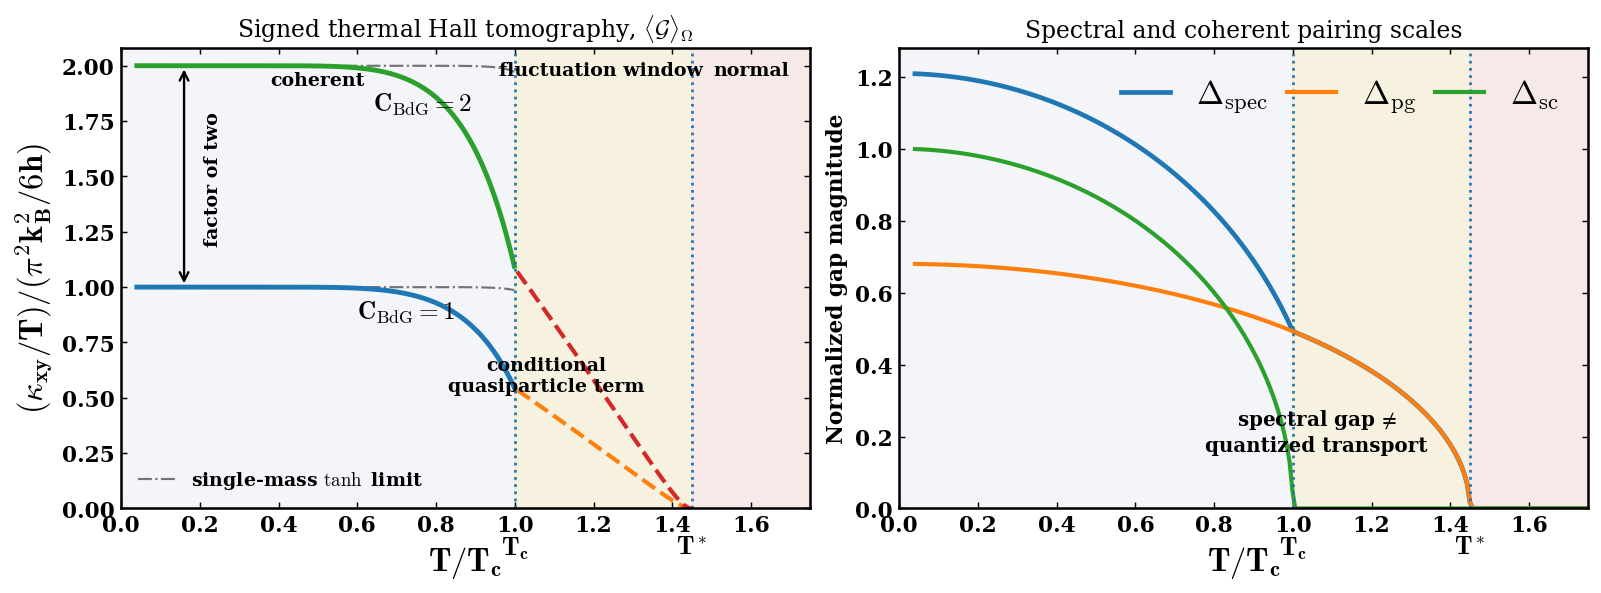

wrote plots_RHG\thermal_hall_tomography_framework_revised.pdf

maximum deviation of the single-mass tanh form from the exact kernel,
below Tc, as a fraction of the plateau: 0.439


In [4]:
t = np.linspace(0.04, 1.75, 240)
d_sc = smooth_gap_below_tc(t)
d_pg = pseudogap_amplitude(t)
d_spec = np.sqrt(d_sc**2 + d_pg**2)

coherent = qp_kernel_exact(d_spec, t)
conditional = qp_kernel_exact(d_pg, t)
coherent_tanh = qp_kernel_tanh(d_spec, t)
below = t <= TC
window = (t >= TC) & (t <= TSTAR)

fig, axes = plt.subplots(1, 2, figsize=(12.2, 4.45), constrained_layout=True)

# --- Panel (a)
ax = axes[0]
ax.axvspan(0, TC, color="#e3e8ee", zorder=0, alpha=0.40)
ax.axvspan(TC, TSTAR, color="#f6efd7", zorder=0, alpha=0.80)
ax.axvspan(TSTAR, t.max(), color="#f7e4e4", zorder=0, alpha=0.80)
for c in (1, 2):
    ax.plot(t[below], c*coherent[below], linewidth=2.7)
    ax.plot(t[window], c*conditional[window], linewidth=2.3, linestyle="--")
    ax.plot(t[below], c*coherent_tanh[below], linewidth=1.2, color="0.45",
            linestyle="-.", zorder=1)
ax.plot([], [], color="0.45", ls="-.", lw=1.2,
        label=r"single-mass $\tanh$ limit")
ax.legend(loc="lower left", frameon=False, fontsize=10.5)
ax.axvline(TC, linestyle=":", linewidth=1.5)
ax.axvline(TSTAR, linestyle=":", linewidth=1.5)
ax.text(0.64, 1.8, r"$\mathbf{C_{\rm BdG}=2}$", fontsize=14)
ax.text(0.60, 0.86, r"$\mathbf{C_{\rm BdG}=1}$", fontsize=14)
ax.annotate("", xy=(0.16, 2.0), xytext=(0.16, 1.0),
            arrowprops={"arrowstyle": "<->", "lw": 1.3})
ax.text(0.21, 1.49, "factor of two", rotation=90, va="center", fontsize=10.5)
ax.text(1.08, 0.53, "conditional\nquasiparticle term", fontsize=10.5,
        ha="center")
ax.text(0.50, 0.95, "coherent", transform=ax.get_xaxis_transform(),
        ha="center", va="top", fontsize=10.5)
ax.text(1.22, 0.97, "fluctuation window", transform=ax.get_xaxis_transform(),
        ha="center", va="top", fontsize=10.5)
ax.text(1.60, 0.97, "normal", transform=ax.get_xaxis_transform(),
        ha="center", va="top", fontsize=10.5)
ax.set_xlim(0, 1.75); ax.set_ylim(0, 2.08)
ax.set_xlabel(r"$\mathbf{T/T_c}$", fontsize=18)
ax.set_ylabel(r"$\mathbf{(\kappa_{xy}/T)/(\pi^2 k_B^2/6h)}$", fontsize=18)
ax.set_title(r"Signed thermal Hall tomography, $\langle\mathcal{G}\rangle_\Omega$")
ax.text(TC, -0.10, r"$\mathbf{T_c}$", ha="center",
        transform=ax.get_xaxis_transform(), fontsize=14)
ax.text(TSTAR, -0.10, r"$\mathbf{T^*}$", ha="center",
        transform=ax.get_xaxis_transform(), fontsize=14)

# --- Panel (b)
ax = axes[1]
ax.axvspan(0, TC, color="#e3e8ee", zorder=0, alpha=0.40)
ax.axvspan(TC, TSTAR, color="#f6efd7", zorder=0, alpha=0.80)
ax.axvspan(TSTAR, t.max(), color="#f7e4e4", zorder=0, alpha=0.80)
ax.plot(t, d_spec, linewidth=2.6, label=r"$\mathbf{\Delta_{\rm spec}}$")
ax.plot(t, d_pg, linewidth=2.3, label=r"$\mathbf{\Delta_{\rm pg}}$")
ax.plot(t, d_sc, linewidth=2.3, label=r"$\mathbf{\Delta_{\rm sc}}$")
ax.axvline(TC, linestyle=":", linewidth=1.5)
ax.axvline(TSTAR, linestyle=":", linewidth=1.5)
ax.text(1.06, 0.16, "spectral gap $\u2260$\nquantized transport",
        fontsize=11, ha="center")
ax.set_xlim(0, 1.75); ax.set_ylim(0, 1.28)
ax.set_xlabel(r"$\mathbf{T/T_c}$", fontsize=18)
ax.set_ylabel("Normalized gap magnitude")
ax.set_title("Spectral and coherent pairing scales")
ax.legend(loc="upper right", frameon=False, ncol=3, columnspacing=0.6,
          handlelength=1.5, fontsize=18)
ax.text(TC, -0.10, r"$\mathbf{T_c}$", ha="center",
        transform=ax.get_xaxis_transform(), fontsize=14)
ax.text(TSTAR, -0.10, r"$\mathbf{T^*}$", ha="center",
        transform=ax.get_xaxis_transform(), fontsize=14)

for axis in axes:
    axis.tick_params(direction="in", top=True, right=True)

fig.savefig(OUT / "thermal_hall_tomography_framework_revised.pdf",
            bbox_inches="tight")
fig.savefig(OUT / "thermal_hall_tomography_framework_revised.png", dpi=300,
            bbox_inches="tight")
plt.show()
print("wrote", OUT / "thermal_hall_tomography_framework_revised.pdf")

print("\nmaximum deviation of the single-mass tanh form from the exact kernel,")
print("below Tc, as a fraction of the plateau:",
      round(float(np.abs(coherent_tanh[below] - coherent[below]).max()), 4))